# CheXagent-2-3b Fine-Tuning — Phrase Grounding (Kaggle T4)

**Setup Kaggle sebelum run:**
1. Upload dataset VinDR-CXR ke Kaggle Datasets → path akan jadi `/kaggle/input/vindr-cxr/`
2. Upload `train.parquet`, `val.parquet`, `test.parquet` ke Kaggle Datasets tersendiri
3. Di notebook settings: **Accelerator → GPU T4 x1**, **Internet → On**
4. Tambah secret `HFTOKEN` di Kaggle Secrets (Settings → Add-ons → Secrets)

## STEP 1 — Install

In [1]:
# import subprocess, sys

# pkgs = [
#     'transformers==4.40.0',
#     'peft==0.10.0',
#     'accelerate==0.29.3',
#     'sentencepiece',
#     'einops',
#     'pydicom',
# ]
# for pkg in pkgs:
#     r = subprocess.run(
#         [sys.executable, '-m', 'pip', 'install', pkg, '-q', '--no-cache-dir'],
#         capture_output=True, text=True
#     )
#     print(f"{'OK' if r.returncode==0 else 'FAIL'} {pkg}")

## STEP 2 — Patch pytorch_utils.py

In [2]:
# import sys, subprocess
# r = subprocess.run(
#     [sys.executable, '-c',
#      'import transformers, os; print(os.path.join(os.path.dirname(transformers.__file__), "pytorch_utils.py"))'],
#     capture_output=True, text=True
# )
# path = r.stdout.strip()
# with open(path) as f:
#     content = f.read()
# if 'is_torch_greater_or_equal_than_2_3' not in content:
#     with open(path, 'a') as f:
#         f.write("""
# # === PATCH ===
# import torch as _tp
# _v = tuple(int(x) for x in _tp.__version__.split("+")[0].split("."))
# is_torch_greater_or_equal_than_2_3 = _v >= (2, 3)
# is_torch_greater_or_equal_than_2_4 = _v >= (2, 4)
# is_torch_greater_or_equal_than_2_5 = _v >= (2, 5)
# """)
#     print('Patch OK:', path)
# else:
#     print('Patch sudah ada.')

In [3]:
# import os
# os.environ["CUDA_VISIBLE_DEVICES"] = "0"

In [4]:
# import torch
# print(torch.cuda.device_count())

## STEP 3 — Import & Verifikasi

In [1]:
import os, re, gc, sys, warnings, tempfile
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset
from tqdm.auto import tqdm
from PIL import Image
import pydicom

import transformers
from transformers import (
    AutoTokenizer, AutoModelForCausalLM, AutoProcessor,
    TrainingArguments, Trainer, EarlyStoppingCallback, 
)
from peft import LoraConfig, get_peft_model, TaskType

warnings.filterwarnings('ignore')

assert transformers.__version__ == '4.40.0'

print('transformers :', transformers.__version__)
print('numpy        :', np.__version__)
print('torch        :', torch.__version__)
print('CUDA         :', torch.cuda.is_available())
print('GPU          :', torch.cuda.get_device_name(0))
print('VRAM         :', round(torch.cuda.get_device_properties(0).total_memory/1e9, 1), 'GB')
print('OK')

d:\nicho\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


transformers : 4.40.0
numpy        : 2.4.6
torch        : 2.5.1+cu121
CUDA         : True
GPU          : NVIDIA GeForce RTX 4060
VRAM         : 8.6 GB
OK


## STEP 4 — Konfigurasi Path (Kaggle)

In [2]:
# ── Sesuaikan nama dataset Kaggle kamu ──────────────────────────────────
# Cek path dengan: import os; print(os.listdir('/kaggle/input/'))

DICOM_DIR    = './vindr-cxr/vindr'          # folder berisi file .dicom
DATASET_PATH = './vindr-cxr' # folder berisi train/val/test.parquet
OUTPUT_DIR   = './output'
MODEL_NAME   = 'StanfordAIMI/CheXagent-2-3b'

MAX_LENGTH   = 1200
BATCH_SIZE   = 1
GRAD_ACCUM   = 8     
NUM_EPOCHS = 1
LR           = 2e-4

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Cek isi /kaggle/input/
# print('Kaggle input datasets:')
# for d in sorted(os.listdir('/kaggle/input')):
#     files = os.listdir(f'/kaggle/input/{d}')[:5]
#     print(f'  /kaggle/input/{d}/ → {files}')
print()
print('Config OK')


Config OK


## STEP 5 — HuggingFace Login & Load Data

In [7]:
# from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

# secrets = UserSecretsClient()
# hf_token = secrets.get_secret('HFTOKEN')
import os; login(os.getenv("HF_TOKEN"))
print('HF login OK')

HF login OK


In [24]:
train_df = pd.read_parquet(os.path.join(DATASET_PATH, 'train.parquet'))
val_df   = pd.read_parquet(os.path.join(DATASET_PATH, 'val.parquet'))
test_df  = pd.read_parquet(os.path.join(DATASET_PATH, 'test.parquet'))

print(f'Train : {len(train_df):,}')
print(f'Val   : {len(val_df):,}')
print(f'Test  : {len(test_df):,}')
display(train_df.head(3))
# print(os.path.join(DATASET_PATH, 'train.parquet'))

Train : 12,467
Val   : 1,568
Test  : 1,562


,image_id,query,response
0,1bf31ecce06f5cab7b82b36daea676b6,Ada berapa banyak temuan?,"<|ref|>Aortic enlargement<|/ref|><|box|>(0, 74..."
1,1bf31ecce06f5cab7b82b36daea676b6,Kelainan apa yang terlihat?,"<|ref|>Aortic enlargement<|/ref|><|box|>(0, 74..."
2,1bf31ecce06f5cab7b82b36daea676b6,Di mana Aortic enlargement?,"<|ref|>Aortic enlargement<|/ref|><|box|>(0, 74..."


In [9]:
# def has_bbox(text):
#     return bool(re.search(r'\[\d+[,\s]+\d+[,\s]+\d+[,\s]+\d+\]', str(text)))

# train_df_grounding = train_df[train_df['response'].apply(has_bbox)].reset_index(drop=True)
# val_df_grounding   = val_df[val_df['response'].apply(has_bbox)].reset_index(drop=True)
# test_df_grounding  = test_df[test_df['response'].apply(has_bbox)].reset_index(drop=True)

# print(f"Train: {len(train_df):,} → {len(train_df_grounding):,} (hanya bbox)")
# print(f"Val  : {len(val_df):,} → {len(val_df_grounding):,}")
# print(f"Test : {len(test_df):,} → {len(test_df_grounding):,}")

# train_df = train_df_grounding.copy()
# val_df = val_df_grounding.copy()
# test_df = test_df_grounding.copy()

## STEP 6 — Load Model
T4 16GB → tidak perlu CPU offload, semua muat di GPU.

In [10]:
print('Loading tokenizer...')
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
processor = AutoProcessor.from_pretrained(MODEL_NAME, trust_remote_code=True)
print('Tokenizer OK')

Loading tokenizer...


Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.
Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


Tokenizer OK


In [11]:
print('Loading model (float16)...')

# bnb_config = BitsAndBytesConfig(
#     load_in_4bit=True,
#     bnb_4bit_quant_type="nf4",
#     bnb_4bit_compute_dtype=torch.bfloat16, # Tetap kencang di RTX 4060
#     bnb_4bit_use_double_quant=True
# )

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True,
    # quantization_config=bnb_config, 
    torch_dtype=torch.bfloat16,
    device_map={'':0}
)
model = model.to("cuda")

# Freeze visual encoder
for param in model.model.visual.parameters():
    param.requires_grad = False

vram_used = torch.cuda.memory_allocated()/1e9
vram_total = torch.cuda.get_device_properties(0).total_memory/1e9
print(f'VRAM dipakai : {vram_used:.2f} GB')
print(f'VRAM bebas   : {vram_total - vram_used:.2f} GB')
print(f'Device       : {next(model.parameters()).device}')

Loading model (float16)...


Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.
Loading checkpoint shards: 100%|██████████| 3/3 [00:03<00:00,  1.15s/it]


VRAM dipakai : 6.29 GB
VRAM bebas   : 2.29 GB
Device       : cuda:0


In [12]:
print(next(model.parameters()).dtype)

torch.bfloat16


## STEP 7 — Setup LoRA

In [13]:
model.gradient_checkpointing_enable()
model.enable_input_require_grads()

lora_config = LoraConfig(
    r=16,                        # T4 16GB bisa pakai r=16
    lora_alpha=32,
    target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj',
                    'gate_proj', 'up_proj', 'down_proj'],
    lora_dropout=0.05,
    bias='none',
    task_type=TaskType.CAUSAL_LM,
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

gc.collect()
torch.cuda.empty_cache()
vram_used = torch.cuda.memory_allocated()/1e9
vram_total = torch.cuda.get_device_properties(0).total_memory/1e9
print(f'VRAM setelah LoRA : {vram_used:.2f} GB')
print(f'VRAM bebas        : {vram_total - vram_used:.2f} GB')

trainable params: 10,223,616 || all params: 3,150,970,368 || trainable%: 0.32445928733024504
VRAM setelah LoRA : 6.31 GB
VRAM bebas        : 2.27 GB


## STEP 8 — Dataset Class

In [19]:
val_df.sample(5)

,image_id,query,response
970,afb41a2217d37b54f0427fc1c69336be,Ada berapa banyak temuan?,"<|ref|>Infiltration<|/ref|><|box|>(21, 36), (3..."
1199,e7a50b38b3dd034c219fad4c10986fe7,Apakah hasil rontgen ini menunjukkan Cardiomeg...,"<|ref|>Cardiomegaly<|/ref|><|box|>(38, 62), (8..."
1255,34bc3d49ab74c913ee2517f5e0f4e09e,Apakah ada Pleural effusion?,"<|ref|>Pleural effusion<|/ref|><|box|>(81, 72)..."
191,ecf474d5d4f65d7a3e23370a68b8c6a0,Di mana Aortic enlargement?,"<|ref|>Aortic enlargement<|/ref|><|box|>(69, 4..."
1483,63415dfe4d7eb0c122a6818e84195475,Apakah hasil rontgen ini menunjukkan Aortic en...,"<|ref|>Aortic enlargement<|/ref|><|box|>(26, 2..."


In [23]:
path_test = "D:/nicho/png_cache"
def check_image_exists(image_id):
    # Di sini otomatis ditambahkan .png di akhir nama filenya
    image_path = os.path.join(path_test, f"{image_id}.png") 
    return os.path.exists(image_path)

# 3. Jalankan pengecekan pada kolom 'image_id'
val_df['file_exists'] = val_df['image_id'].apply(check_image_exists)

# 4. Tampilkan hasil ringkasannya
missing_images = val_df[~val_df['file_exists']]
total_missing = len(missing_images)

print(f"Total baris di val_df : {len(val_df)}")
print(f"Gambar yang ADA       : {val_df['file_exists'].sum()}")
print(f"Gambar yang HILANG    : {total_missing}")

# 5. Opsional: Hapus baris yang gambarnya tidak ada agar tidak bikin error saat training
if total_missing > 0:
    print(f"\n⚠️ Menghapus {total_missing} baris karena gambar tidak ditemukan.")
    # Hanya menyisakan data yang file_exists == True
    val_df = val_df[val_df['file_exists']].drop(columns=['file_exists'])
else:
    print("\n✅ Aman! Semua gambar lengkap dan ada di folder.")
    val_df = val_df.drop(columns=['file_exists'])

Total baris di val_df : 1568
Gambar yang ADA       : 1568
Gambar yang HILANG    : 0

✅ Aman! Semua gambar lengkap dan ada di folder.


In [25]:
test_exists = os.path.join(path_test, f"{val_df.iloc[1]['image_id']}.png") 
print(test_exists)
print(os.path.exists(test_exists))

D:/nicho/png_cache\4ce311cd58824cdd3b6ca3e0878bb9c1.png
True


In [27]:
# SYSTEM_PROMPT = (
#     'You are a radiology AI assistant. '
#     'When asked about findings in a chest X-ray, respond with the finding name '
#     'followed by normalized bounding box coordinates in [x1, y1, x2, y2] format '
#     'where values range from 0 to 1000.'
# )
SYSTEM_PROMPT = (
    'Kamu adalah asisten AI radiologi. '
    'Ketika ditanya tentang temuan pada foto rontgen dada, jawab dengan nama temuan '
    'diikuti koordinat bounding box yang dinormalisasi dalam format [x1, y1, x2, y2] '
    'dengan nilai antara 0 hingga 1000.'
)
def dicom_to_pil(image_id: str) -> Image.Image:
    # Cari file .dicom — bisa tersimpan flat atau dalam subfolder
    candidates = [
        os.path.join(DICOM_DIR, f'{image_id}.dicom'),
        os.path.join(DICOM_DIR, f'{image_id}.dcm'),
        os.path.join(DICOM_DIR, 'train_images', f'{image_id}.dicom'),
        os.path.join(DICOM_DIR, 'test_images',  f'{image_id}.dicom'),
    ]
    path = next((p for p in candidates if os.path.exists(p)), None)
    if path is None:
        print(f'[WARN] File tidak ditemukan: {image_id}')
        return Image.new('RGB', (512, 512), 0)
    try:
        dcm = pydicom.dcmread(path)
        arr = dcm.pixel_array.astype(np.float32)
        lo, hi = arr.min(), arr.max()
        if hi > lo:
            arr = (arr - lo) / (hi - lo)
        arr = (arr * 255).astype(np.uint8)
        return Image.fromarray(arr).convert('RGB')
    except Exception as e:
        print(f'[WARN] DICOM {image_id}: {e}')
        return Image.new('RGB', (512, 512), 0)


CACHE_DIR = "./png_cache"
os.makedirs(CACHE_DIR, exist_ok=True)
import time
from tqdm import tqdm
from joblib import Parallel, delayed

image_ids = np.union1d(
    train_df["image_id"].values, 
    np.union1d(val_df["image_id"].values, test_df["image_id"].values)
)

# images_ids = 

start = time.time()
pbar = tqdm(total=len(image_ids), desc="Caching")

def process(image_id):
    path = os.path.join(CACHE_DIR, f"{image_id}.png")
    if not os.path.exists(path):
        img = dicom_to_pil(image_id)
        img.save(path, "PNG")
    pbar.update(1)

Parallel(n_jobs=6, backend="threading")(
    delayed(process)(i) for i in image_ids
)

pbar.close()

print("Total time:", time.time() - start, "seconds")

def is_valid_image(path):
    try:
        with Image.open(path) as img:
            img.verify()
        return True
    except:
        return False

class GroundingDataset(Dataset):
    def __init__(self, df, tokenizer, max_length=MAX_LENGTH):
        self.df        = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len   = max_length
        self.img_tok   = tokenizer.convert_tokens_to_ids('<image>')

    def __len__(self):
        return len(self.df)

    def _empty(self):
        ids = torch.zeros(self.max_len, dtype=torch.long)
        return {
            'input_ids':      ids,
            'attention_mask': torch.zeros(self.max_len, dtype=torch.long),
            'labels':         torch.full((self.max_len,), -100, dtype=torch.long),
        }

    def __getitem__(self, idx):
        row      = self.df.iloc[idx]
        image_id = str(row['image_id'])
        question = str(row['query'])
        answer   = str(row['response'])
    
        try:
            img_path = os.path.join(CACHE_DIR, f"{image_id}.png")

    
            if not os.path.exists(img_path):
                print(f"[WARN] missing cache: {image_id}")
                img_path = None
            
            if (img_path is None) or (not os.path.exists(img_path)) or (not is_valid_image(img_path)):
                return self._empty()
    
            fq = self.tokenizer.from_list_format([
                {"image": img_path},
                {"text": question},
            ])
    
            full_conv = [
                {"from": "system", "value": SYSTEM_PROMPT},
                {"from": "human",  "value": fq},
                {"from": "gpt",    "value": answer},
            ]
    
            instr_conv = [
                {"from": "system", "value": SYSTEM_PROMPT},
                {"from": "human",  "value": fq},
            ]
    
            full_tok = self.tokenizer.apply_chat_template(
                full_conv,
                add_generation_prompt=False,
                tokenize=True,
                return_dict=True,
                return_tensors="pt",
                padding="max_length",
                max_length=self.max_len,
                truncation=True,
            )
    
            instr_tok = self.tokenizer.apply_chat_template(
                instr_conv,
                add_generation_prompt=True,
                tokenize=True,
                return_dict=True,
                return_tensors="pt",
            )
    
            instr_len = instr_tok["input_ids"].shape[-1]
            instr_len = min(instr_len, full_tok["input_ids"].shape[1] - 1)
    
            ids = full_tok["input_ids"].squeeze(0)
    
            if (ids == self.img_tok).sum().item() == 0:
                print(f"[WARN] image token hilang: {image_id}")
                return self._empty()
    
            labels = full_tok["input_ids"].squeeze(0).clone()

            input_ids = labels.clone()

            # cari boundary secara aman:
            instr_len = instr_tok["input_ids"].shape[-1]
            instr_len = min(instr_len, input_ids.shape[0])

            # mask hanya prompt
            labels[:instr_len] = -100

            # mask padding
            labels[input_ids == self.tokenizer.pad_token_id] = -100
    
            return {
                "input_ids": ids,
                "attention_mask": full_tok["attention_mask"].squeeze(0),
                "labels": labels.squeeze(0),
            }
    
        except Exception as e:
            print(f"[WARN] {image_id}: {e}")
            return self._empty()

def bersihkan_dataframe(df):
    indices_valid = []
    for idx, row in df.iterrows():
        image_id = str(row['image_id'])
        img_path = os.path.join(CACHE_DIR, f"{image_id}.png")
        
        # Cek 1: Apakah file png-nya ada di cache?
        # Cek 2: Apakah file-nya valid (bisa dibuka/tidak korup)?
        if os.path.exists(img_path) and is_valid_image(img_path):
            indices_valid.append(idx)
            
    return df.loc[indices_valid].reset_index(drop=True)

# Bersihkan train dan val dataframe dari data hantu/korup
print(f"Jumlah awal val_df: {len(val_df)}")
train_df = bersihkan_dataframe(train_df)
val_df = bersihkan_dataframe(val_df)
print(f"Jumlah val_df setelah dibersihkan: {len(val_df)}")

# Baru masukkan ke dataset setelah bersih
train_dataset = GroundingDataset(train_df, tokenizer)
val_dataset   = GroundingDataset(val_df,   tokenizer)

# val_dataset = torch.utils.data.Subset(val_dataset, [0])
print(train_df.shape)
print(val_df.shape)
print(test_df.shape)
print(len(train_dataset))
s = train_dataset[1]
n_resp = (s['labels'] != -100).sum().item()
print(f'input_ids      : {s["input_ids"].shape}')
valid = 0
for i in range(100):
    s = train_dataset[i]
    n = (s["labels"] != -100).sum().item()
    if n > 0:
        valid += 1

print("valid ratio:", valid/100)
print(f'response tokens: {n_resp}  <- harus > 0')
assert n_resp > 0, 'ERROR: response tokens = 0'
print('Dataset OK')

Caching: 100%|██████████| 3892/3892 [00:00<00:00, 27571.31it/s]


Total time: 0.14316415786743164 seconds
Jumlah awal val_df: 1568
Jumlah val_df setelah dibersihkan: 1563


NameError: name 'tokenizer' is not defined

## STEP 9 — Collate & Trainer

In [15]:
def collate_fn(batch):
    return {
        'input_ids':      torch.stack([b['input_ids']      for b in batch]),
        'attention_mask': torch.stack([b['attention_mask'] for b in batch]),
        'labels':         torch.stack([b['labels']         for b in batch]),
    }


class NoMoveTrainer(Trainer):
    """Skip _move_model_to_device — model sudah di GPU yang benar."""
    def _move_model_to_device(self, model, device):
        pass


training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LR,
    lr_scheduler_type='cosine',
    warmup_ratio=0.05,
    weight_decay=0.01,
    fp16=False,
    bf16=True,
    gradient_checkpointing=True,
    optim='adamw_torch',
    logging_steps=50,
    evaluation_strategy='steps',
    eval_steps=500,
    save_strategy='steps',
    save_steps=500,
    load_best_model_at_end=True,
    metric_for_best_model='eval_loss',
    greater_is_better=False,
    save_total_limit=20,
    remove_unused_columns=False,
    dataloader_num_workers=0,   
    report_to='none',
)

import types
from transformers.models.phi.modeling_phi import PhiAttention

# Ambil fungsi forward asli
original_phi_attn_forward = PhiAttention.forward

def uncasted_forward(self, hidden_states, *args, **kwargs):
    # Pastikan di-cast ke bfloat16, karena training_args menggunakan bf16=True
    if isinstance(hidden_states, torch.Tensor):
        hidden_states = hidden_states.to(torch.bfloat16)
    
    return original_phi_attn_forward(self, hidden_states, *args, **kwargs)

# Terapkan patch ke model
patched_count = 0
for name, module in model.named_modules():
    if module.__class__.__name__ == "PhiAttention":
        module.forward = types.MethodType(uncasted_forward, module)
        patched_count += 1

print(f"Berhasil mem-patch {patched_count} modul PhiAttention ke BFloat16.")


trainer = NoMoveTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=tokenizer,
    data_collator=collate_fn,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

print('Trainer siap')

Berhasil mem-patch 32 modul PhiAttention ke BFloat16.
Trainer siap


## STEP 10 — Training

In [16]:
# visual = model.base_model.model.model.visual

# print(next(visual.parameters()).dtype)

In [17]:
# visual = model.base_model.model.model.visual

# visual.half()

In [18]:
# Ambil modul visual
visual = model.base_model.model.model.visual
print("Dtype awal visual:", next(visual.parameters()).dtype)

# PAKSA KE BFLOAT16 (Jangan gunakan .half() karena .half() itu Float16!)
visual.to(torch.bfloat16) 
print("Dtype setelah diubah:", next(visual.parameters()).dtype)

Dtype awal visual: torch.float32
Dtype setelah diubah: torch.bfloat16


In [19]:
nan_count = sum(
    1 for _, p in model.named_parameters()
    if p.requires_grad and torch.isnan(p).any()
)

print("NaN params:", nan_count)

NaN params: 0


In [20]:
print("args.max_steps:", trainer.args.max_steps)
print("state.max_steps:", trainer.state.max_steps)
print("global_step:", trainer.state.global_step)
print("epoch:", trainer.state.epoch)

args.max_steps: -1
state.max_steps: 0
global_step: 0
epoch: None


In [ ]:
gc.collect()
torch.cuda.empty_cache()

vram_used  = torch.cuda.memory_allocated()/1e9
vram_total = torch.cuda.get_device_properties(0).total_memory/1e9
print(f'VRAM dipakai   : {vram_used:.2f} GB')
print(f'VRAM bebas     : {vram_total - vram_used:.2f} GB')
print(f'Mulai training...')

result = trainer.train()

adapter_path = os.path.join(OUTPUT_DIR, 'lora_adapter')
model.save_pretrained(adapter_path)
tokenizer.save_pretrained(adapter_path)
trainer.save_metrics('train', result.metrics)

print('Selesai!')
print(result.metrics)

VRAM dipakai   : 6.31 GB
VRAM bebas     : 2.27 GB
Mulai training...


  3%|▎         | 50/1558 [38:53<19:30:48, 46.58s/it]

{'loss': 2.51, 'grad_norm': 1.2578125, 'learning_rate': 0.00012820512820512823, 'epoch': 0.03}


  6%|▋         | 100/1558 [1:17:38<18:48:22, 46.43s/it]

{'loss': 0.8679, 'grad_norm': 0.69921875, 'learning_rate': 0.00019989097834957799, 'epoch': 0.06}


 10%|▉         | 150/1558 [1:56:25<18:11:51, 46.53s/it]

... (18 outputs left out)

{'loss': 0.6497, 'grad_norm': 0.74609375, 'learning_rate': 0.0001538691303862744, 'epoch': 0.35}


 39%|███▊      | 600/1558 [8:09:15<12:17:34, 46.19s/it]

{'loss': 0.6457, 'grad_norm': 0.6484375, 'learning_rate': 0.00014464088757135728, 'epoch': 0.39}


 39%|███▉      | 612/1558 [8:18:49<13:26:51, 51.18s/it]

## STEP 11 — Evaluasi Test Set

In [ ]:
test_dataset = GroundingDataset(test_df, tokenizer)
metrics      = trainer.evaluate(test_dataset)

print('=== Test Metrics ===')
for k, v in metrics.items():
    print(f'  {k}: {v:.4f}' if isinstance(v, float) else f'  {k}: {v}')

100%|██████████| 1646/1646 [25:37<00:00,  1.07it/s]

=== Test Metrics ===
  eval_loss: nan
  eval_runtime: 1538.5380
  eval_samples_per_second: 1.0700
  eval_steps_per_second: 1.0700
  epoch: 0.1813


## STEP 12 — Inference & Visualisasi

Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


Query: Sisi mana yang menunjukkan kelainan?
GT   : Kelainan yang teridentifikasi di dalam kotak pembatas yang ditentukan terletak di sisi kiri pasien, kemungkinan melibatkan zona paru bagian bawah kiri [481, 325, 614, 426].


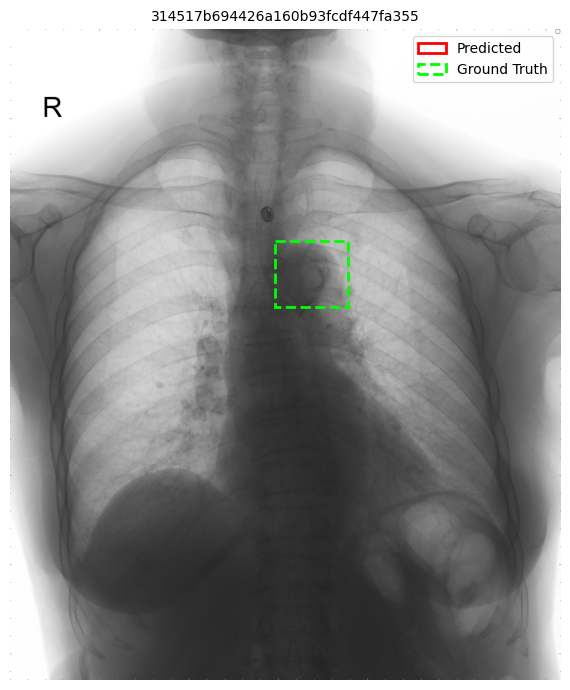

Response: Ya, Cardiomegaly [5, 5, 5, 5] dan Aortic enlargement [5, 5, 5, 5] [6, 6, 6, 6] ditanya mencantumkan pada kortu [5, 5, 5, 5] dan


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


def parse_bbox(text):
    m = re.search(r'\[(\d+)[,\s]+(\d+)[,\s]+(\d+)[,\s]+(\d+)\]', text)
    return list(map(int, m.groups())) if m else None


def compute_iou(a, b):
    ix1 = max(a[0],b[0]); iy1 = max(a[1],b[1])
    ix2 = min(a[2],b[2]); iy2 = min(a[3],b[3])
    inter = max(0,ix2-ix1)*max(0,iy2-iy1)
    union = (a[2]-a[0])*(a[3]-a[1])+(b[2]-b[0])*(b[3]-b[1])-inter
    return inter/union if union > 0 else 0.0


@torch.no_grad()
def predict(image_id: str, question: str, max_new_tokens=64) -> dict:
    img_path = os.path.join(CACHE_DIR, f"{image_id}.png")
    if not os.path.exists(img_path):
        print(f"[WARN] missing cache: {image_id}")
        img_path = None
    
    if (img_path is None) or (not os.path.exists(img_path)) or (not is_valid_image(img_path)):
        return self._empty()
    image = Image.open(img_path)
    try:
        fq = tokenizer.from_list_format([{'image': img_path}, {'text': question}])
        conv = [
            {'from': 'system', 'value': SYSTEM_PROMPT},
            {'from': 'human',  'value': fq},
        ]
        inputs = tokenizer.apply_chat_template(
            conv, add_generation_prompt=True,
            tokenize=True, return_dict=True, return_tensors='pt'
        ).to(model.device)
        
        out      = model.generate(**inputs, max_new_tokens=max_new_tokens)
        response = tokenizer.decode(
            out[0][inputs['input_ids'].shape[-1]:],
            skip_special_tokens=True
        )
        return {'response': response, 'bbox': parse_bbox(response), 'image': image}
    finally:
        try:
            os.remove(tmp_path)
        except Exception:
            pass


def visualize(result, image_id, gt_bbox=None):
    img  = result['image']
    w, h = img.size
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(img, cmap='gray')
    ax.set_title(image_id, fontsize=10)
    if result['bbox']:
        x1,y1,x2,y2 = [v/1000 for v in result['bbox']]
        ax.add_patch(mpatches.Rectangle(
            (x1*w,y1*h),(x2-x1)*w,(y2-y1)*h,
            lw=2,edgecolor='red',facecolor='none',label='Predicted'))
    if gt_bbox:
        gx1,gy1,gx2,gy2 = [v/1000 for v in gt_bbox]
        ax.add_patch(mpatches.Rectangle(
            (gx1*w,gy1*h),(gx2-gx1)*w,(gy2-gy1)*h,
            lw=2,edgecolor='lime',facecolor='none',
            linestyle='--',label='Ground Truth'))
        if result['bbox']:
            iou = compute_iou(result['bbox'], gt_bbox)
            ax.set_xlabel(f'IoU = {iou:.3f}', fontsize=11)
    ax.legend()
    ax.axis('off')
    plt.tight_layout()
    plt.show()
    print('Response:', result['response'])


# Test inference
row    = test_df.sample(1, random_state=42).iloc[0]
gt_box = parse_bbox(str(row['response']))
print(f'Query: {row["query"]}')
print(f'GT   : {row["response"]}')
result = predict(row['image_id'], row['query'])
visualize(result, row['image_id'], gt_box)

## STEP 13 — Batch Evaluasi IoU

In [ ]:
records = []
for _, row in tqdm(test_df.iterrows(), total=len(test_df), desc='Evaluating'):
    res      = predict(row['image_id'], row['query'])
    gt_box   = parse_bbox(str(row['response']))
    pred_box = res['bbox']
    iou      = compute_iou(pred_box, gt_box) if (pred_box and gt_box) else None
    records.append({
        'image_id':  row['image_id'],
        'query':     row['query'],
        'gt':        gt_box,
        'pred':      pred_box,
        'pred_text': res['response'],
        'iou':       iou,
    })

results_df = pd.DataFrame(records)
valid      = results_df['iou'].dropna()

print(f'Total sampel       : {len(results_df):,}')
print(f'Berhasil grounding : {len(valid):,} ({len(valid)/len(results_df)*100:.1f}%)')
print(f'Mean IoU           : {valid.mean():.4f}')
print(f'Median IoU         : {valid.median():.4f}')
print(f'IoU@0.5            : {(valid >= 0.5).mean()*100:.1f}%')
print(f'IoU@0.25           : {(valid >= 0.25).mean()*100:.1f}%')

out = os.path.join(OUTPUT_DIR, 'test_results.csv')
results_df.to_csv(out, index=False)
print(f'Disimpan: {out}')

Evaluating:  50%|████▉     | 818/1646 [37:02<37:29,  2.72s/it]


NameError: name 'self' is not defined

---
## Checklist Sebelum Run di Kaggle

| # | Yang harus dilakukan | Cara |
|---|---|---|
| 1 | Upload file DICOM VinDR | Kaggle → Datasets → New Dataset → upload zip |
| 2 | Upload train/val/test.parquet | Kaggle → Datasets → New Dataset terpisah |
| 3 | Tambah kedua dataset ke notebook | Notebook → Add Data → Your Datasets |
| 4 | Set Accelerator = GPU T4 x1 | Notebook → Settings → Accelerator |
| 5 | Set Internet = On | Notebook → Settings → Internet |
| 6 | Tambah HFTOKEN ke Secrets | Settings → Add-ons → Secrets → Add |
| 7 | Sesuaikan `DICOM_DIR` dan `DATASET_PATH` | STEP 4 — cek output listdir |

## Estimasi Waktu di Kaggle T4

| | Lokal RTX 3060 | Kaggle T4 |
|---|---|---|
| VRAM | 6.4 GB (tidak cukup) | 15 GB ✅ |
| Detik/iter | ~550 det (CPU) | ~8-15 det |
| Total 5 epoch | ~632 jam | ~11-17 jam |
| Batas Kaggle | — | 30 jam/minggu |